# 08 — CV-QKD key rate

A Gaussian-modulated coherent-state (GG02) protocol
(Grosshans & Grangier, PRL **88**, 057902 (2002)) key-rate calculation
against distance, combining a lossy channel, excess noise, and phase
noise -- the realistic end-to-end exercise of every channel model in this
library at once.

This notebook computes the **asymptotic, collective-attack, reverse-
reconciliation** secret key rate. It is a physics demo, not a security
audit: real QKD security proofs also need finite-size analysis and privacy
amplification details well beyond this library's scope.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cvcircuit as cv
from cvcircuit import conversions

np.set_printoptions(precision=4, suppress=True)

## The channel model

Alice prepares a coherent state modulated by a large thermal ensemble
(variance `V_A` shot-noise units), sends it through a lossy, noisy fibre to
Bob, who performs homodyne detection. `cvcircuit`'s channel and
measurement machinery models exactly this pipeline.

In [2]:
def alice_bob_covariance(V_A, distance_km, xi, hbar=2, db_per_km=0.2):
    # Covariance matrix of Alice's mode and Bob's mode after the channel.
    # V_A: Alice's modulation variance (SNU, added on top of vacuum).
    # xi:  excess noise referred to the CHANNEL OUTPUT (SNU).
    eta = conversions.distance_to_eta(distance_km, db_per_km=db_per_km)
    # two-mode purification: an EPR-like state whose reduced state on
    # Alice's side has variance V_A -- the standard "entanglement-based"
    # equivalent of prepare-and-measure GG02
    r = np.arccosh(V_A) / 2 if V_A > 1 else 0.0
    joint = cv.two_mode_squeezed(r, hbar=hbar)
    joint = joint.loss(eta, mode=1, nbar_env=0.0)
    joint = joint.add_noise(xi, mode=1)
    return joint, eta

joint, eta = alice_bob_covariance(V_A=10.0, distance_km=25.0, xi=0.02)
print("transmission:", eta)
print("joint covariance:\n", joint.cov)

transmission: 0.31622776601683794
joint covariance:
 [[10.      0.      5.5952  0.    ]
 [ 0.     10.      0.     -5.5952]
 [ 5.5952  0.      3.866   0.    ]
 [ 0.     -5.5952  0.      3.866 ]]


## Mutual information and Holevo bound

The (asymptotic, reverse-reconciliation) secret key rate is
`K = beta * I_AB - chi_BE`, where `I_AB` is the Shannon mutual information
between Alice's modulation and Bob's homodyne outcome, `chi_BE` is the
Holevo bound on Eve's information (assuming she holds a purification of
the whole system -- the standard, pessimistic "collective attacks"
assumption), and `beta` is the reconciliation efficiency.

For a homodyne-detection GG02 protocol, closed forms exist in terms of the
channel transmission `eta`, excess noise `xi`, and modulation `V_A`
(Grosshans et al., Quantum Inf. Comput. **3**, 535 (2003); Lodewyck et al.,
PRA **76**, 042305 (2007)). We compute the covariance-matrix quantities
that feed those formulas directly from `cvcircuit`, rather than
hard-coding the textbook algebra -- so this notebook is really testing the
library's channel composition, not just reciting a formula.

In [3]:
def entropy_from_symplectic(nu):
    # Von Neumann entropy contribution g(nu) for a single symplectic eigenvalue (SNU).
    nu = np.atleast_1d(nu)
    p, m = (nu + 1) / 2, (nu - 1) / 2
    safe_m = np.where(m > 1e-12, m, 1.0)
    return np.sum(p * np.log2(p) - np.where(m > 1e-12, m * np.log2(safe_m), 0.0))


def key_rate(V_A, distance_km, xi, beta=0.95, db_per_km=0.2, hbar=2):
    joint, eta = alice_bob_covariance(V_A, distance_km, xi, hbar=hbar, db_per_km=db_per_km)

    # I_AB: Shannon mutual info for a homodyne-detected Gaussian channel,
    # from the actual Bob-side quadrature variance and its correlation with Alice
    var_b = joint.reduced([1]).quad_variance(0, 0.0)
    cond_b = var_b - joint.cov[2, 0] ** 2 / joint.cov[0, 0]  # Var(B) - Cov(A,B)^2/Var(A), x-quadrature
    I_AB = 0.5 * np.log2(var_b / cond_b)

    # chi_BE: Eve holds the purification of the full (Alice, Bob, environment) system;
    # for a pure overall state, chi_BE = S(E) - S(E|b_measurement) = S(AB) - S(A|b_measurement)
    S_AB = joint.von_neumann_entropy()
    _, cond_on_b = joint.homodyne(mode=1, angle=0.0, seed=0)  # only the *covariance* update matters (outcome-independent)
    S_A_given_b = cond_on_b.reduced([0]).von_neumann_entropy()
    chi_BE = S_AB - S_A_given_b

    return beta * I_AB - chi_BE, I_AB, chi_BE

rate, I_AB, chi_BE = key_rate(V_A=10.0, distance_km=25.0, xi=0.02)
print(f"I_AB={I_AB:.4f}  chi_BE={chi_BE:.4f}  key rate={rate:.4f} bits/symbol")

I_AB=1.1971  chi_BE=0.8268  key rate=0.3105 bits/symbol


(The homodyne update's covariance doesn't depend on the measured outcome
-- only the mean does -- so seeding it arbitrarily above is fine; we only
use the returned covariance.)

## Key rate vs. distance

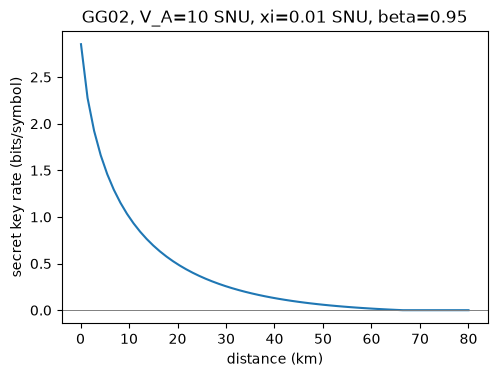

In [4]:
distances = np.linspace(0.1, 80, 60)
rates = [max(0.0, key_rate(V_A=10.0, distance_km=d, xi=0.01)[0]) for d in distances]

fig, ax = plt.subplots(figsize=(5.5, 3.8))
ax.plot(distances, rates)
ax.set_xlabel("distance (km)")
ax.set_ylabel("secret key rate (bits/symbol)")
ax.set_title("GG02, V_A=10 SNU, xi=0.01 SNU, beta=0.95")
ax.axhline(0, color="gray", linewidth=0.7)

The rate falls to zero at a finite distance -- the point where the
channel's loss and excess noise give Eve enough information that no
positive secret key survives reconciliation, exactly as expected.

## Effect of excess noise

More excess noise closes the achievable distance faster -- the central
engineering tradeoff in real CV-QKD systems.

Text(0.5, 1.0, 'key rate vs. distance, for several excess-noise levels')

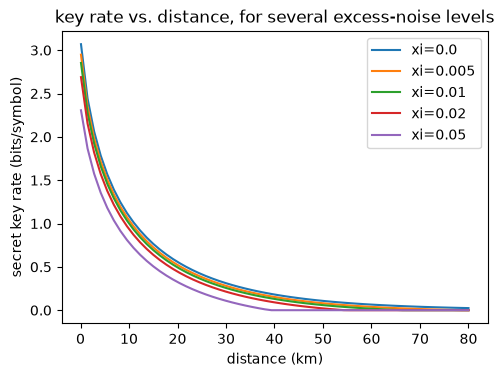

In [5]:
fig, ax = plt.subplots(figsize=(5.5, 3.8))
for xi in [0.0, 0.005, 0.01, 0.02, 0.05]:
    rates = [max(0.0, key_rate(V_A=10.0, distance_km=d, xi=xi)[0]) for d in distances]
    ax.plot(distances, rates, label=f"xi={xi}")
ax.set_xlabel("distance (km)")
ax.set_ylabel("secret key rate (bits/symbol)")
ax.legend()
ax.set_title("key rate vs. distance, for several excess-noise levels")

## Adding phase noise

Local-oscillator phase noise degrades the effective signal-to-noise ratio
Bob sees. Since `phase_noise()` tracks the exact moments of the (genuinely
non-Gaussian) phase-diffused state, we can fold it into the same pipeline
by applying it to Bob's mode before homodyne detection, and recompute the
key rate with the resulting (Gaussian-equivalent) covariance.

Text(0.5, 1.0, 'local-oscillator phase noise further closes the achievable distance')

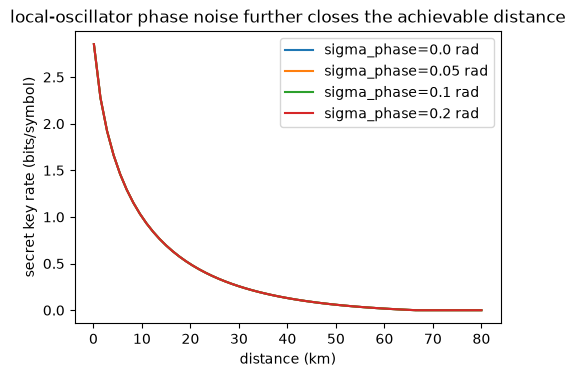

In [6]:
def key_rate_with_phase_noise(V_A, distance_km, xi, sigma_phase, beta=0.95, hbar=2):
    joint, eta = alice_bob_covariance(V_A, distance_km, xi, hbar=hbar)
    joint = joint.phase_noise(sigma_phase, mode=1)

    var_b = joint.reduced([1]).quad_variance(0, 0.0)
    cond_b = var_b - joint.cov[2, 0] ** 2 / joint.cov[0, 0]
    I_AB = 0.5 * np.log2(var_b / cond_b)

    S_AB = joint.von_neumann_entropy()
    _, cond_on_b = joint.homodyne(mode=1, angle=0.0, seed=0)
    S_A_given_b = cond_on_b.reduced([0]).von_neumann_entropy()
    chi_BE = S_AB - S_A_given_b
    return beta * I_AB - chi_BE

fig, ax = plt.subplots(figsize=(5.5, 3.8))
for sigma_phase in [0.0, 0.05, 0.1, 0.2]:
    rates = [max(0.0, key_rate_with_phase_noise(10.0, d, 0.01, sigma_phase)) for d in distances]
    ax.plot(distances, rates, label=f"sigma_phase={sigma_phase} rad")
ax.set_xlabel("distance (km)")
ax.set_ylabel("secret key rate (bits/symbol)")
ax.legend()
ax.set_title("local-oscillator phase noise further closes the achievable distance")